# EDA (Hotel Booking Demand)

## Langkah 1 - Import library

In [1]:
# Fitrya Irfan_202431073
# Langkah 1: import library
import pandas as pd
import matplotlib.pyplot as plt


## Langkah 2 - Baca dataset dan tampilkan datanya

In [2]:
# Fitrya Irfan_202431073
# Langkah 2: baca dataset dan tampilkan datanya
df = pd.read_csv("hotel_bookings.csv")
print(df)
print("Ukuran dataset (baris x kolom):", df.shape)


               hotel  is_canceled  lead_time  arrival_date_year  \
0       Resort Hotel            0        342               2015   
1       Resort Hotel            0        737               2015   
2       Resort Hotel            0          7               2015   
3       Resort Hotel            0         13               2015   
4       Resort Hotel            0         14               2015   
...              ...          ...        ...                ...   
119385    City Hotel            0         23               2017   
119386    City Hotel            0        102               2017   
119387    City Hotel            0         34               2017   
119388    City Hotel            0        109               2017   
119389    City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
0                    July                        27   
1                    July                        27   
2                    July     

## Langkah 3 - Informasi data

In [3]:
# Fitrya Irfan_202431073
# Langkah 3: informasi data
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

## Langkah 4 - Deskripsi statistik

In [4]:
# Fitrya Irfan_202431073
# Langkah 4: deskripsi statistik
print(df.describe())


         is_canceled      lead_time  arrival_date_year  \
count  119390.000000  119390.000000      119390.000000   
mean        0.370416     104.011416        2016.156554   
std         0.482918     106.863097           0.707476   
min         0.000000       0.000000        2015.000000   
25%         0.000000      18.000000        2016.000000   
50%         0.000000      69.000000        2016.000000   
75%         1.000000     160.000000        2017.000000   
max         1.000000     737.000000        2017.000000   

       arrival_date_week_number  arrival_date_day_of_month  \
count             119390.000000              119390.000000   
mean                  27.165173                  15.798241   
std                   13.605138                   8.780829   
min                    1.000000                   1.000000   
25%                   16.000000                   8.000000   
50%                   28.000000                  16.000000   
75%                   38.000000            

## Langkah 5 - Data kosong tiap kolom

In [5]:
# Fitrya Irfan_202431073
# Langkah 5: hitung data kosong tiap kolom
print(df.isna().sum())


hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

## Langkah 6 - Isi unik kolom kategorik

In [6]:
# Fitrya Irfan_202431073
# Langkah 6: isi unik kolom kategorik
kolom_kategori = df.select_dtypes(exclude="number").columns
for kolom in kolom_kategori:
    isi = df[kolom].unique()
    print(kolom, "->", len(isi), "nilai unik")
    if len(isi) <= 12:
        print(list(isi))
    else:
        print("10 contoh pertama:", list(isi[:10]))
    print("-" * 40)


hotel -> 2 nilai unik
['Resort Hotel', 'City Hotel']
----------------------------------------
arrival_date_month -> 12 nilai unik
['July', 'August', 'September', 'October', 'November', 'December', 'January', 'February', 'March', 'April', 'May', 'June']
----------------------------------------
meal -> 5 nilai unik
['BB', 'FB', 'HB', 'SC', 'Undefined']
----------------------------------------
country -> 178 nilai unik
10 contoh pertama: ['PRT', 'GBR', 'USA', 'ESP', 'IRL', 'FRA', nan, 'ROU', 'NOR', 'OMN']
----------------------------------------
market_segment -> 8 nilai unik
['Direct', 'Corporate', 'Online TA', 'Offline TA/TO', 'Complementary', 'Groups', 'Undefined', 'Aviation']
----------------------------------------
distribution_channel -> 5 nilai unik
['Direct', 'Corporate', 'TA/TO', 'Undefined', 'GDS']
----------------------------------------
reserved_room_type -> 10 nilai unik
['C', 'A', 'D', 'E', 'G', 'F', 'H', 'L', 'P', 'B']
----------------------------------------
assigned_room_

## Langkah 7 - Isi data kosong (modus untuk kategorik, mean untuk angka)

In [7]:
# Fitrya Irfan_202431073
# Langkah 7: isi data kosong dan simpan kembali ke dataset
for kolom in df.columns:
    if df[kolom].isna().sum() > 0:
        if not pd.api.types.is_numeric_dtype(df[kolom]):
            df[kolom] = df[kolom].fillna(df[kolom].mode()[0])   # kategorik -> modus
        else:
            df[kolom] = df[kolom].fillna(df[kolom].mean())      # angka -> mean

print("Sisa data kosong:", df.isna().sum().sum())


Sisa data kosong: 0


## Langkah 8 - Hitung data duplikat

In [8]:
# Fitrya Irfan_202431073
# Langkah 8: hitung data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())


Jumlah data duplikat: 32013


## Langkah 9 - Hapus data duplikat dan cek dengan info()

In [9]:
# Fitrya Irfan_202431073
# Langkah 9: hapus data duplikat lalu cek hasilnya
df = df.drop_duplicates()
df.info()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 87377 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87377 non-null  object 
 1   is_canceled                     87377 non-null  int64  
 2   lead_time                       87377 non-null  int64  
 3   arrival_date_year               87377 non-null  int64  
 4   arrival_date_month              87377 non-null  object 
 5   arrival_date_week_number        87377 non-null  int64  
 6   arrival_date_day_of_month       87377 non-null  int64  
 7   stays_in_weekend_nights         87377 non-null  int64  
 8   stays_in_week_nights            87377 non-null  int64  
 9   adults                          87377 non-null  int64  
 10  children                        87377 non-null  float64
 11  babies                          87377 non-null  int64  
 12  meal                           

## Langkah 10 - Visualisasi grafik batang

Online TA        51616
Offline TA/TO    13886
Direct           11798
Groups            4940
Corporate         4206
Complementary      702
Aviation           227
Undefined            2
Name: market_segment, dtype: int64


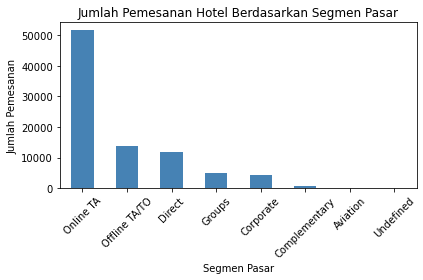

In [10]:
# Fitrya Irfan_202431073
# Langkah 10: grafik batang jumlah tiap kategori
jumlah = df["market_segment"].value_counts()
print(jumlah)

jumlah.plot(kind="bar", color="steelblue")
plt.title("Jumlah Pemesanan Hotel Berdasarkan Segmen Pasar")
plt.xlabel("Segmen Pasar")
plt.ylabel("Jumlah Pemesanan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
